# Laboratorio 4 — Análisis Exploratorio de Datos (EDA)
**Universidad Técnica Nacional** · Minería de Datos ISW-911 · Asignación grupal (investigación)

**Integrantes del grupo:**
1. Eliam Araya Alvarado
2. ___________________________
3. ___________________________
4. ___________________________

---
### Conjunto de datos
**Estadísticas Policiales del OIJ — año 2025** (01/01/2025 al 31/12/2025).
- **Fuente:** Organismo de Investigación Judicial, portal de datos abiertos del Poder Judicial de Costa Rica
  (<https://pjenlinea3.poder-judicial.go.cr/estadisticasoij/>), licencia **CC-BY**.
- **Contenido:** una fila por cada delito denunciado: tipo de delito, fecha, franja horaria, tipo de víctima,
  edad, sexo, nacionalidad y ubicación (provincia y cantón).
- El archivo CSV se publicó en GitHub y **se lee directamente desde allí** (punto 3).

### Documentación interna del proceso
Cada sección del notebook corresponde a un punto del enunciado. Antes de cada bloque de código
se explica **qué se hace y por qué** (justificación de las decisiones del EDA).

In [1]:
# Librerías utilizadas
import csv
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Configuración visual
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 1–3. Lectura del conjunto de datos desde GitHub
El dataset está en un repositorio **público** de GitHub y se lee con su URL *raw*.

**Problema de calidad detectado en el archivo original del OIJ:**
1. El **encabezado no coincide con los datos**: dice `Fecha, Victima, … Canton, Distrito`, pero cada fila trae
   `Fecha, Hora, Victima, … Provincia, Canton` (falta *Hora* en el encabezado y *Distrito* no existe).
   Todas las líneas terminan con una coma, lo que genera una columna vacía extra.
2. **Cuatro filas tienen 13 campos** porque la nacionalidad contiene una coma sin comillas
   (por ejemplo `VIRGENES BRITANICAS, ISLAS`).

**Solución:** se ignora el encabezado original y se asignan los nombres correctos; las filas de 13 campos
se reparan uniendo los dos pedazos de la nacionalidad con la función `unir_nacionalidad`.

In [2]:
# URL "raw" del archivo publicado en GitHub
URL_DATASET = "https://raw.githubusercontent.com/ElaiM02/WORKSHOP_4_Mineria/main/data/estadisticas_oij_2025.csv"

# Evidencia del problema: las primeras líneas tal como vienen en el archivo
with urllib.request.urlopen(URL_DATASET) as respuesta:
    texto = respuesta.read().decode("utf-8")
for linea in texto.splitlines()[:3]:
    print(linea)

Delito,SubDelito,Fecha,Victima,SubVictima,Edad,Sexo,Nacionalidad,Provincia,Canton,Distrito,
ASALTO,ARMA BLANCA,2025-01-06,00:00:00 - 02:59:59,PERSONA,PEATON [PERSONA],Desconocido,MUJER,NICARAGUA,SAN JOSE,SAN JOSE,
ASALTO,ARMA BLANCA,2025-01-09,18:00:00 - 20:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,COSTA RICA,SAN JOSE,DESAMPARADOS,


In [3]:
# Nombres reales de las columnas según el contenido de las filas
COLUMNAS_REALES = ["Delito", "SubDelito", "Fecha", "Hora", "Victima", "SubVictima",
                   "Edad", "Sexo", "Nacionalidad", "Provincia", "Canton", "Vacia"]

def unir_nacionalidad(campos):
    """Repara filas con 13 campos: la nacionalidad venía partida por una coma."""
    return campos[:8] + [campos[8] + "," + campos[9]] + campos[10:]

df = pd.read_csv(io.StringIO(texto), header=None, skiprows=1, names=COLUMNAS_REALES,
                 engine="python", on_bad_lines=unir_nacionalidad)

filas_13 = sum(1 for f in csv.reader(io.StringIO(texto)) if len(f) == 13)
print(f"Filas leídas: {len(df):,} | filas reparadas (13 campos): {filas_13}")

Filas leídas: 41,073 | filas reparadas (13 campos): 4


## 4. Funciones básicas para visualizar las características del conjunto de datos

In [4]:
# Dimensiones: (filas, columnas)
print("Dimensiones:", df.shape)
print("Columnas:", list(df.columns))

Dimensiones: (41073, 12)
Columnas: ['Delito', 'SubDelito', 'Fecha', 'Hora', 'Victima', 'SubVictima', 'Edad', 'Sexo', 'Nacionalidad', 'Provincia', 'Canton', 'Vacia']


In [5]:
# Primeras filas
df.head()

,Delito,SubDelito,Fecha,Hora,Victima,SubVictima,Edad,Sexo,Nacionalidad,Provincia,Canton,Vacia
0,ASALTO,ARMA BLANCA,2025-01-06,00:00:00 - 02:59:59,PERSONA,PEATON [PERSONA],Desconocido,MUJER,NICARAGUA,SAN JOSE,SAN JOSE,NaN
1,ASALTO,ARMA BLANCA,2025-01-09,18:00:00 - 20:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,COSTA RICA,SAN JOSE,DESAMPARADOS,NaN
2,ASALTO,ARMA BLANCA,2025-01-11,06:00:00 - 08:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,MUJER,COSTA RICA,SAN JOSE,PURISCAL,NaN
3,ASALTO,ARMA BLANCA,2025-01-08,03:00:00 - 05:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,NICARAGUA,SAN JOSE,SAN JOSE,NaN
4,ASALTO,ARMA BLANCA,2025-01-15,03:00:00 - 05:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,NICARAGUA,HEREDIA,HEREDIA,NaN


In [6]:
# Últimas filas
df.tail()

,Delito,SubDelito,Fecha,Hora,Victima,SubVictima,Edad,Sexo,Nacionalidad,Provincia,Canton,Vacia
41068,TACHA DE VEHICULO,TACHA DE VEHICULO,2025-12-29,09:00:00 - 11:59:59,VEHICULO,AUTOMOVIL [VEHICULO],Mayor de edad,HOMBRE,ESTADOS UNIDOS,PUNTARENAS,GARABITO,NaN
41069,TACHA DE VEHICULO,TACHA DE VEHICULO,2025-12-30,15:00:00 - 17:59:59,VEHICULO,CARGA LIVIANA [VEHICULO],Adulto Mayor,HOMBRE,Desconocido,HEREDIA,FLORES,NaN
41070,TACHA DE VEHICULO,TACHA DE VEHICULO,2025-12-31,12:00:00 - 14:59:59,VEHICULO,AUTOMOVIL [VEHICULO],Mayor de edad,HOMBRE,COSTA RICA,SAN JOSE,SAN JOSE,NaN
41071,TACHA DE VEHICULO,TACHA DE VEHICULO,2025-12-31,12:00:00 - 14:59:59,VEHICULO,AUTOMOVIL [VEHICULO],Mayor de edad,MUJER,COSTA RICA,CARTAGO,OREAMUNO,NaN
41072,TACHA DE VEHICULO,TACHA DE VEHICULO,2025-12-29,00:00:00 - 02:59:59,VEHICULO,OTRO O INDETERMINADO [VEHICULO],Mayor de edad,MUJER,CANADA,PUNTARENAS,OSA,NaN


In [7]:
# Muestra aleatoria de filas
df.sample(5, random_state=42)

,Delito,SubDelito,Fecha,Hora,Victima,SubVictima,Edad,Sexo,Nacionalidad,Provincia,Canton,Vacia
18819,ROBO,BOQUETE,2025-05-20,00:00:00 - 02:59:59,VIVIENDA,NO APLICA [VIVIENDA],Adulto Mayor,HOMBRE,COSTA RICA,SAN JOSE,TARRAZU,NaN
25438,ASALTO,INMOVILIZACION,2025-06-24,03:00:00 - 05:59:59,VEHICULO,CARGA LIVIANA [VEHICULO],Mayor de edad,HOMBRE,COSTA RICA,SAN JOSE,SAN JOSE,NaN
29526,ROBO DE VEHICULO,DESCUIDO,2025-07-22,03:00:00 - 05:59:59,VEHICULO,MICROBUS [VEHICULO],Mayor de edad,HOMBRE,COSTA RICA,SAN JOSE,SAN JOSE,NaN
36201,HURTO,POR DESCUIDO,2025-08-24,21:00:00 - 23:59:59,OTROS,BICICLETA [OTROS],Mayor de edad,HOMBRE,NICARAGUA,HEREDIA,SAN PABLO,NaN
26738,ROBO,FORZADURA,2025-02-26,00:00:00 - 02:59:59,VIVIENDA,NO APLICA [VIVIENDA],Mayor de edad,HOMBRE,COSTA RICA,SAN JOSE,DOTA,NaN


In [8]:
# Tipos de datos, valores no nulos y memoria
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41073 entries, 0 to 41072
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Delito        41073 non-null  str    
 1   SubDelito     41073 non-null  str    
 2   Fecha         41073 non-null  str    
 3   Hora          41073 non-null  str    
 4   Victima       41073 non-null  str    
 5   SubVictima    41073 non-null  str    
 6   Edad          41073 non-null  str    
 7   Sexo          41073 non-null  str    
 8   Nacionalidad  41073 non-null  str    
 9   Provincia     41073 non-null  str    
 10  Canton        41073 non-null  str    
 11  Vacia         0 non-null      float64
dtypes: float64(1), str(11)
memory usage: 3.8 MB


In [9]:
# Estadística descriptiva (todas las columnas son categóricas: cantidad, únicos, valor más frecuente)
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Delito,41073,6,HURTO,13554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubDelito,41073,39,POR DESCUIDO,7578,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fecha,41073,365,2025-11-01,192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hora,41073,8,00:00:00 - 02:59:59,7964,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Victima,41073,5,PERSONA,16593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubVictima,41073,87,PEATON [PERSONA],10010,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Edad,41073,4,Mayor de edad,34196,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sexo,41073,3,HOMBRE,25386,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nacionalidad,41073,82,COSTA RICA,31764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Provincia,41073,8,SAN JOSE,16126,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Cantidad de valores distintos por columna
df.nunique().sort_values(ascending=False)

Fecha           365
SubVictima       87
Canton           85
Nacionalidad     82
SubDelito        39
Hora              8
Provincia         8
Delito            6
Victima           5
Edad              4
Sexo              3
Vacia             0
dtype: int64

In [11]:
# Frecuencia de cada tipo de delito
df["Delito"].value_counts()

Delito
HURTO                13554
ASALTO                9584
ROBO                  7560
ROBO DE VEHICULO      5155
TACHA DE VEHICULO     4350
HOMICIDIO              870
Name: count, dtype: int64

In [12]:
# Filas duplicadas exactas
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 2812


**Observaciones iniciales**
- Todas las variables son **categóricas** (texto); la fecha viene como texto `YYYY-MM-DD` y la hora como franja de 3 horas.
- La columna `Vacia` no tiene ningún valor (es producto de la coma final de cada línea).
- Existen filas duplicadas exactas. **No se eliminan**: el archivo no trae un identificador del caso y la información
  está agregada (día, franja horaria y cantón), por lo que dos delitos distintos —por ejemplo, dos hurtos el mismo día,
  en la misma franja y cantón— producen filas idénticas. Eliminarlas subestimaría la criminalidad.

## 5. Cambio de nombres de las columnas a español
Las columnas ya estaban en español, pero se renombran a nombres **descriptivos, en minúscula y sin tildes**
(estilo *snake_case*), lo que facilita su uso en código y corrige los nombres engañosos del archivo original.

In [13]:
nombres_es = {
    "Delito": "delito",
    "SubDelito": "subdelito",
    "Fecha": "fecha",
    "Hora": "rango_hora",
    "Victima": "tipo_victima",
    "SubVictima": "subtipo_victima",
    "Edad": "grupo_edad",
    "Sexo": "sexo",
    "Nacionalidad": "nacionalidad",
    "Provincia": "provincia",
    "Canton": "canton",
    "Vacia": "columna_vacia",
}
df = df.rename(columns=nombres_es)
df.columns.tolist()

['delito',
 'subdelito',
 'fecha',
 'rango_hora',
 'tipo_victima',
 'subtipo_victima',
 'grupo_edad',
 'sexo',
 'nacionalidad',
 'provincia',
 'canton',
 'columna_vacia']

## 6. Determinación de valores nulos
Se revisan dos tipos de nulos:
1. **Nulos explícitos** (`NaN`): celdas vacías.
2. **Nulos disfrazados**: textos como `Desconocido` o `DESCONOCIDO` que en realidad significan *dato faltante*.

In [14]:
# 6.1 Nulos explícitos
nulos_explicitos = df.isna().sum()
nulos_explicitos

delito                 0
subdelito              0
fecha                  0
rango_hora             0
tipo_victima           0
subtipo_victima        0
grupo_edad             0
sexo                   0
nacionalidad           0
provincia              0
canton                 0
columna_vacia      41073
dtype: int64

In [15]:
# 6.2 Nulos disfrazados: valores que indican que el dato no se conoce
VALORES_DESCONOCIDOS = ["Desconocido", "DESCONOCIDO"]
disfrazados = df.isin(VALORES_DESCONOCIDOS).sum()
disfrazados[disfrazados > 0]

subdelito         29
grupo_edad      2862
sexo            2461
nacionalidad    2723
provincia          3
canton           126
dtype: int64

In [16]:
# Se convierten a NaN para tratarlos como lo que son: datos faltantes
df = df.replace(VALORES_DESCONOCIDOS, np.nan)

resumen_nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
}).sort_values("porcentaje", ascending=False)
resumen_nulos

,nulos,porcentaje
columna_vacia,41073,100.00
grupo_edad,2862,6.97
nacionalidad,2723,6.63
sexo,2461,5.99
canton,126,0.31
subdelito,29,0.07
provincia,3,0.01
delito,0,0.00
rango_hora,0,0.00
fecha,0,0.00


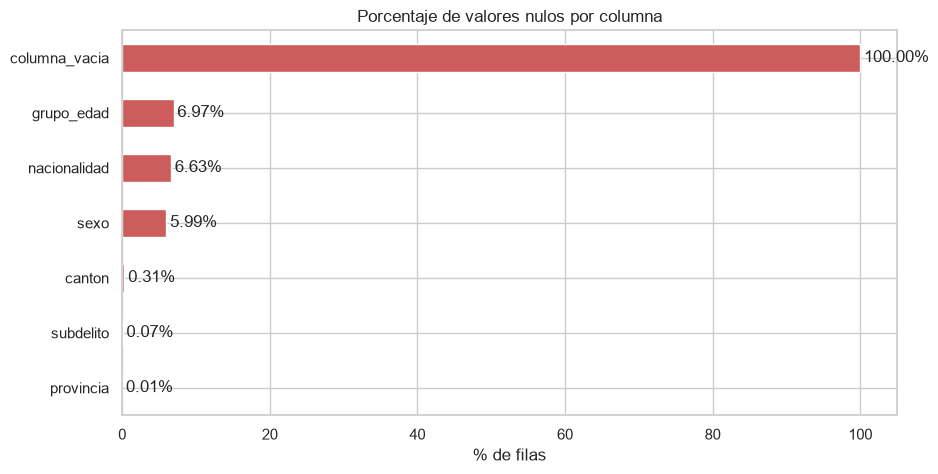

In [17]:
# Evidencia gráfica 1: porcentaje de nulos por columna
con_nulos = resumen_nulos[resumen_nulos["nulos"] > 0]
ax = con_nulos["porcentaje"].plot(kind="barh", color="indianred")
ax.set_title("Porcentaje de valores nulos por columna")
ax.set_xlabel("% de filas")
for i, v in enumerate(con_nulos["porcentaje"]):
    ax.text(v + 0.5, i, f"{v:.2f}%", va="center")
ax.invert_yaxis()
plt.show()

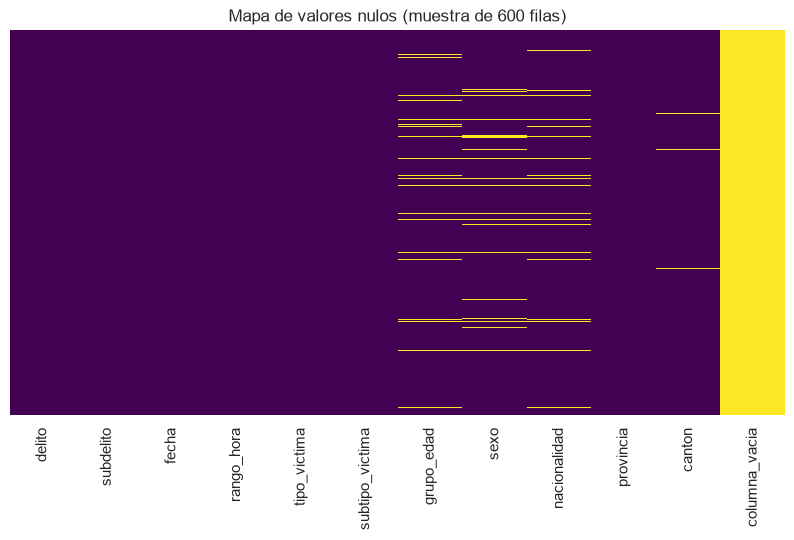

In [18]:
# Evidencia gráfica 2: mapa de nulos (muestra de 600 filas); cada línea clara es un dato faltante
muestra = df.sample(600, random_state=1)
plt.figure(figsize=(10, 5))
sns.heatmap(muestra.isna(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de valores nulos (muestra de 600 filas)")
plt.show()

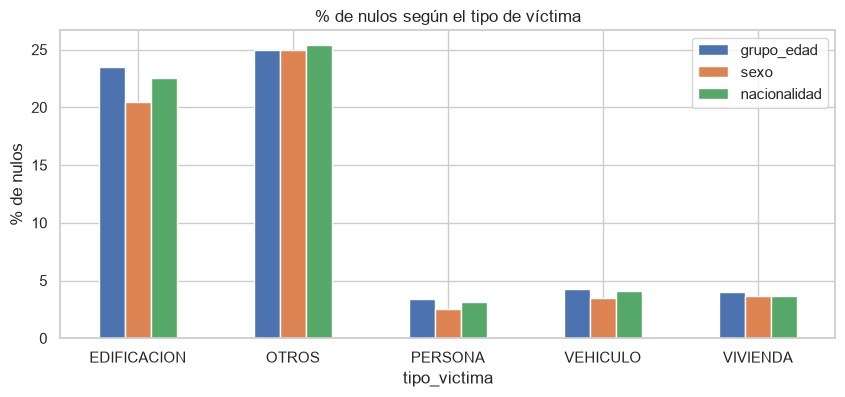

,grupo_edad,sexo,nacionalidad
tipo_victima,,,
EDIFICACION,23.5,20.5,22.5
OTROS,25.0,25.0,25.4
PERSONA,3.4,2.5,3.1
VEHICULO,4.3,3.5,4.1
VIVIENDA,4.0,3.7,3.7


In [19]:
# ¿Los nulos de edad, sexo y nacionalidad dependen del tipo de víctima?
pct_nulos_victima = (df[["grupo_edad", "sexo", "nacionalidad"]].isna()
                     .groupby(df["tipo_victima"]).mean() * 100).round(1)
pct_nulos_victima.plot(kind="bar", figsize=(10, 4), rot=0,
                       title="% de nulos según el tipo de víctima")
plt.ylabel("% de nulos")
plt.show()
pct_nulos_victima

**Hallazgos sobre nulos**
- No hay nulos explícitos salvo `columna_vacia`, que está **100 % vacía** → no aporta información.
- Al convertir los "Desconocido" en nulos aparecen los faltantes reales: `grupo_edad` (6,97 %),
  `nacionalidad` (6,63 %) y `sexo` (5,99 %).
- `canton` tiene **126 filas** sin ubicación (0,31 %), 3 de ellas también sin provincia.
- `subdelito` tiene 29 nulos (0,07 %); no se imputa porque esa columna se excluye del dataset final (ver punto 10).
- El tercer gráfico muestra que los faltantes **no son aleatorios**: cuando la víctima es una *edificación* u *otros*,
  entre el 20 % y el 25 % de los datos de la persona se desconocen, contra solo un 3 % cuando la víctima es una persona.
  Por eso se imputan con la moda **por grupo** y no con una moda global (ver punto 8).

## 7. Determinación de valores atípicos
Los valores atípicos solo tienen sentido en variables **numéricas**, y este dataset es completamente categórico.
Por eso se **derivan variables numéricas** a partir de la fecha, la hora y la ubicación:

| Variable derivada | Significado |
|---|---|
| `hora_inicio` | hora en que inicia la franja horaria (0, 3, 6, …, 21) |
| `mes` | mes del delito (1–12) |
| `dia_semana` | día de la semana (0 = lunes … 6 = domingo) |
| `delitos_dia` | cantidad total de delitos registrados ese día en el país |
| `delitos_canton` | cantidad total de delitos del año en ese cantón |

In [20]:
fecha_tmp = pd.to_datetime(df["fecha"], format="%Y-%m-%d")
df["hora_inicio"] = df["rango_hora"].str.slice(0, 2).astype(int)
df["mes"] = fecha_tmp.dt.month
df["dia_semana"] = fecha_tmp.dt.day_of_week
df["delitos_dia"] = df.groupby("fecha")["delito"].transform("count")
df["delitos_canton"] = df.groupby("canton")["delito"].transform("count")

NUMERICAS = ["hora_inicio", "mes", "dia_semana", "delitos_dia", "delitos_canton"]
df[NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
hora_inicio,41073.0,10.683442,7.354381,0.0,3.0,12.0,18.0,21.0
mes,41073.0,6.506975,3.455855,1.0,3.0,7.0,9.0,12.0
dia_semana,41073.0,3.080393,2.007561,0.0,1.0,3.0,5.0,6.0
delitos_dia,41073.0,114.865654,17.076058,72.0,103.0,113.0,124.0,192.0
delitos_canton,40947.0,2662.216255,3414.343915,28.0,379.0,1017.0,2756.0,8988.0


In [21]:
def detectar_atipicos_iqr(serie):
    """Devuelve límites y cantidad de atípicos según el rango intercuartílico (IQR)."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    atipicos = ((serie < inferior) | (serie > superior)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "lim_inferior": inferior,
                      "lim_superior": superior, "atipicos": atipicos,
                      "%_atipicos": round(atipicos / len(serie) * 100, 2)})

df[NUMERICAS].apply(detectar_atipicos_iqr).T

,Q1,Q3,IQR,lim_inferior,lim_superior,atipicos,%_atipicos
hora_inicio,3.0,18.0,15.0,-19.5,40.5,0.0,0.00
mes,3.0,9.0,6.0,-6.0,18.0,0.0,0.00
dia_semana,1.0,5.0,4.0,-5.0,11.0,0.0,0.00
delitos_dia,103.0,124.0,21.0,71.5,155.5,857.0,2.09
delitos_canton,379.0,2756.0,2377.0,-3186.5,6321.5,8988.0,21.88


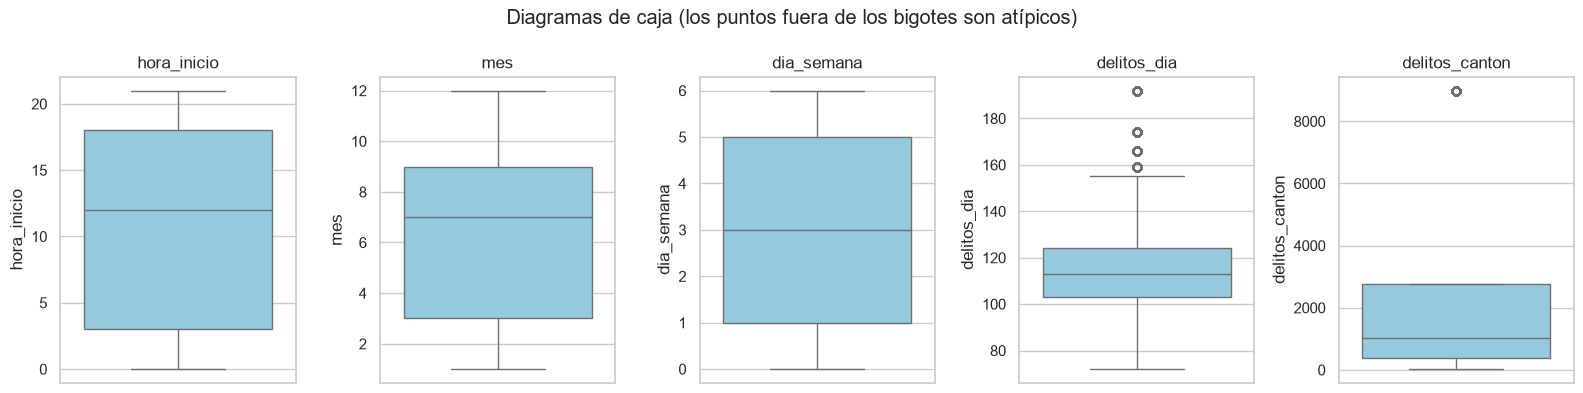

In [22]:
# Evidencia gráfica 1: diagramas de caja de las variables numéricas
fig, ejes = plt.subplots(1, len(NUMERICAS), figsize=(16, 4))
for eje, col in zip(ejes, NUMERICAS):
    sns.boxplot(y=df[col], ax=eje, color="skyblue")
    eje.set_title(col)
plt.suptitle("Diagramas de caja (los puntos fuera de los bigotes son atípicos)")
plt.tight_layout()
plt.show()

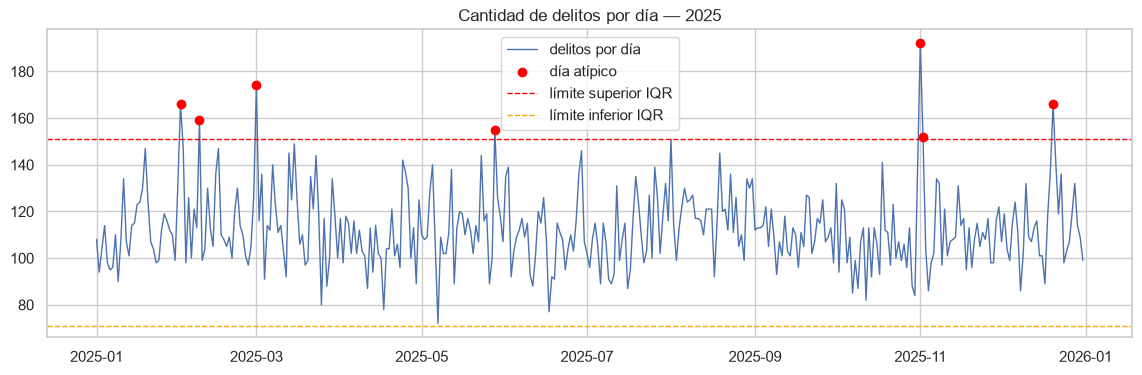

Días atípicos:
fecha
2025-11-01    192
2025-03-01    174
2025-02-01    166
2025-12-20    166
2025-02-08    159
2025-05-28    155
2025-11-02    152


In [23]:
# Evidencia gráfica 2: delitos por día durante 2025, marcando los días atípicos
por_dia = df.groupby("fecha").size()
lim = detectar_atipicos_iqr(por_dia)
plt.figure(figsize=(14, 4))
plt.plot(pd.to_datetime(por_dia.index), por_dia.values, lw=1, label="delitos por día")
atip = por_dia[(por_dia > lim["lim_superior"]) | (por_dia < lim["lim_inferior"])]
plt.scatter(pd.to_datetime(atip.index), atip.values, color="red", zorder=3, label="día atípico")
plt.axhline(lim["lim_superior"], color="red", ls="--", lw=1, label="límite superior IQR")
plt.axhline(lim["lim_inferior"], color="orange", ls="--", lw=1, label="límite inferior IQR")
plt.title("Cantidad de delitos por día — 2025")
plt.legend()
plt.show()
print("Días atípicos:")
print(atip.sort_values(ascending=False).to_string())

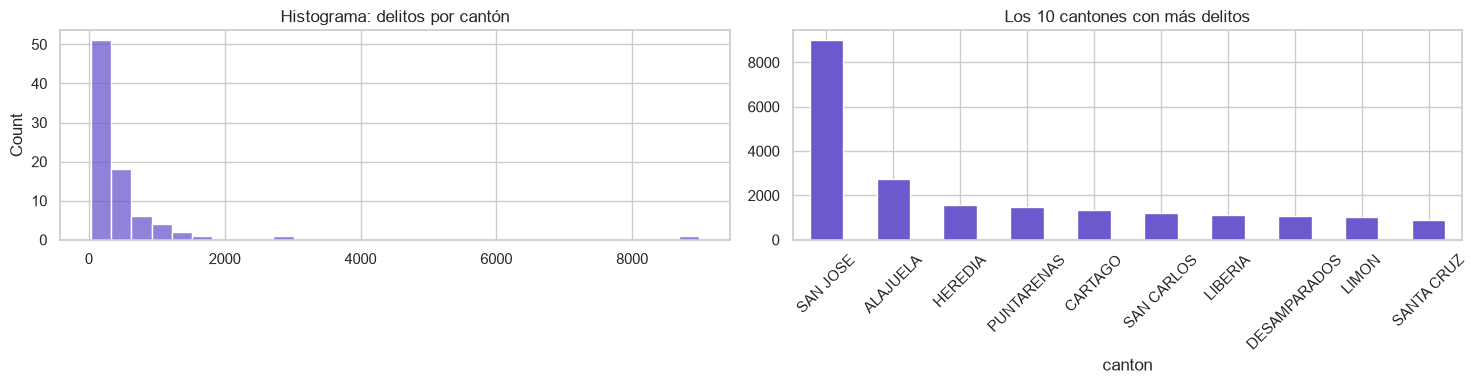

In [24]:
# Evidencia gráfica 3: distribución de delitos por cantón (muy sesgada a la derecha)
por_canton = df.groupby("canton").size().sort_values(ascending=False)
fig, ejes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(por_canton, bins=30, ax=ejes[0], color="slateblue")
ejes[0].set_title("Histograma: delitos por cantón")
por_canton.head(10).plot(kind="bar", ax=ejes[1], color="slateblue", rot=45)
ejes[1].set_title("Los 10 cantones con más delitos")
plt.tight_layout()
plt.show()

**Hallazgos sobre atípicos**
- `hora_inicio`, `mes` y `dia_semana` **no tienen atípicos**: son valores acotados (0–21, 1–12, 0–6).
- `delitos_dia` tiene **7 días atípicos** (2,1 % de las filas), todos por encima del límite de 155,5 delitos.
  Varios son el **primer día del mes** (1 de febrero, 1 de marzo y 1 de noviembre, con 192 delitos el máximo),
  lo que sugiere denuncias acumuladas que se registran con esa fecha.
- `delitos_canton` es **muy asimétrica**: el cantón de San José tiene 8 988 delitos, frente a una mediana de 1 017.
  El método IQR marca como atípicas todas sus filas (21,9 %). No es un error: es la concentración urbana real
  de la criminalidad.

## 8. Funciones de imputación y tratamiento (sobre los hallazgos de los puntos 6 y 7)

| Hallazgo | Acción | Justificación |
|---|---|---|
| `columna_vacia` 100 % nula | **Eliminar la columna** | No contiene información; imputarla sería inventar datos. |
| `provincia`/`canton` nulos (126 filas) | **Eliminar las filas** | Son el 0,31 % de los datos; el cantón no se puede deducir de otras columnas y una moda (San José) sesgaría la ubicación. |
| `grupo_edad` y `sexo` nulos (~6–7 %) | **Moda por grupo** (`tipo_victima` + `delito`) | Son categóricas (no hay media ni mediana). La moda por grupo respeta que el perfil de la víctima cambia según el tipo de delito y de víctima. |
| `nacionalidad` nula (~7 %) | **Moda por grupo** (`provincia`) | La nacionalidad predominante varía por zona (por ejemplo, más turistas en Guanacaste y Puntarenas). |
| `delitos_dia` con días atípicos | **Recorte (*capping*) a los límites IQR** | Los picos son reales pero extremos; recortarlos conserva el orden de los días sin que dominen la escala. |
| `delitos_canton` asimétrica | **Transformación logarítmica** `log(1+x)` | Los valores altos son reales (no errores); el logaritmo reduce la asimetría sin eliminar información. |

In [25]:
def eliminar_columnas_vacias(datos, umbral=0.9):
    """Elimina las columnas cuyo porcentaje de nulos es mayor o igual al umbral."""
    vacias = datos.columns[datos.isna().mean() >= umbral].tolist()
    print(f"Columnas eliminadas: {vacias}")
    return datos.drop(columns=vacias)


def eliminar_filas_nulas(datos, columnas):
    """Elimina las filas que tienen nulos en las columnas indicadas."""
    antes = len(datos)
    datos = datos.dropna(subset=columnas)
    print(f"Filas eliminadas por nulos en {columnas}: {antes - len(datos)}")
    return datos


def imputar_moda(datos, columna):
    """Reemplaza los nulos de una columna por su valor más frecuente (moda global)."""
    moda = datos[columna].mode()[0]
    n = datos[columna].isna().sum()
    datos[columna] = datos[columna].fillna(moda)
    print(f"{columna}: {n} nulos imputados con la moda global '{moda}'")
    return datos


def imputar_moda_por_grupo(datos, columna, grupos):
    """Reemplaza los nulos por la moda de su grupo; si el grupo no tiene moda, usa la moda global."""
    n = datos[columna].isna().sum()
    moda_grupo = datos.groupby(grupos)[columna].transform(
        lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan)
    datos[columna] = datos[columna].fillna(moda_grupo)
    restantes = datos[columna].isna().sum()
    if restantes:
        datos = imputar_moda(datos, columna)
    print(f"{columna}: {n} nulos imputados con la moda por {grupos}")
    return datos


def recortar_atipicos_iqr(datos, columna):
    """Capping: los valores fuera de [Q1-1.5*IQR, Q3+1.5*IQR] se reemplazan por el límite."""
    q1, q3 = datos[columna].quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((datos[columna] < inferior) | (datos[columna] > superior)).sum()
    datos[columna] = datos[columna].clip(inferior, superior)
    print(f"{columna}: {n} valores atípicos recortados a [{inferior:.1f}, {superior:.1f}]")
    return datos


def transformar_logaritmo(datos, columna):
    """Aplica log(1+x) para reducir la asimetría de una variable con valores extremos reales."""
    antes = datos[columna].skew()
    datos[columna] = np.log1p(datos[columna])
    print(f"{columna}: asimetría {antes:.2f} -> {datos[columna].skew():.2f}")
    return datos

In [26]:
# Aplicación de las funciones
df = eliminar_columnas_vacias(df)
df = eliminar_filas_nulas(df, ["provincia", "canton"])
df = imputar_moda_por_grupo(df, "grupo_edad", ["tipo_victima", "delito"])
df = imputar_moda_por_grupo(df, "sexo", ["tipo_victima", "delito"])
df = imputar_moda_por_grupo(df, "nacionalidad", ["provincia"])
df = recortar_atipicos_iqr(df, "delitos_dia")
df = transformar_logaritmo(df, "delitos_canton")
df = df.reset_index(drop=True)

Columnas eliminadas: ['columna_vacia']
Filas eliminadas por nulos en ['provincia', 'canton']: 126
grupo_edad: 2838 nulos imputados con la moda por ['tipo_victima', 'delito']
sexo: 2440 nulos imputados con la moda por ['tipo_victima', 'delito']
nacionalidad: 2700 nulos imputados con la moda por ['provincia']
delitos_dia: 855 valores atípicos recortados a [71.5, 155.5]
delitos_canton: asimetría 1.24 -> 0.16


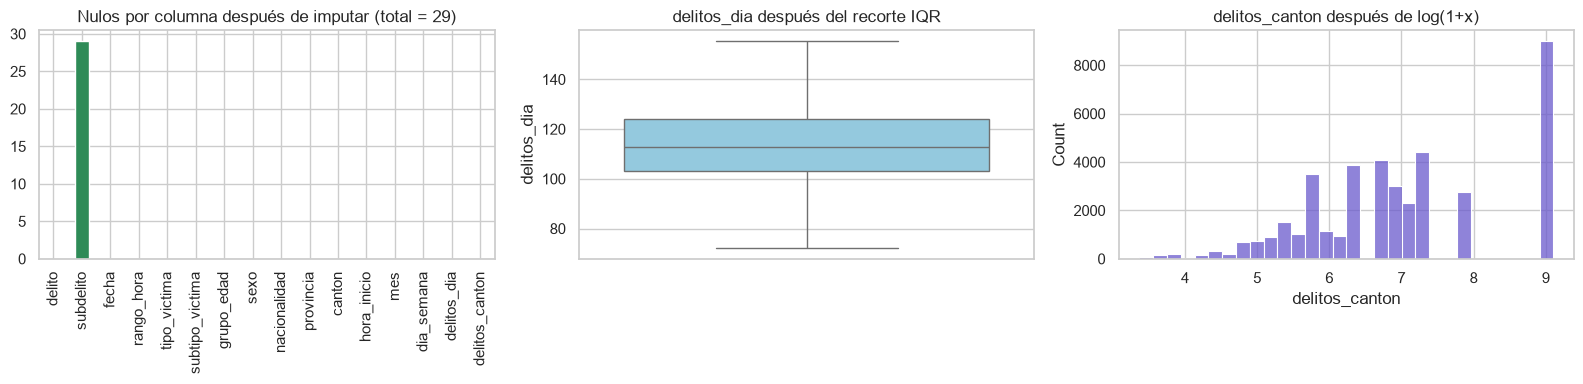

In [27]:
# Verificación gráfica: después del tratamiento no quedan nulos ni atípicos en delitos_dia
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
df.isna().sum().plot(kind="bar", ax=ejes[0], color="seagreen", rot=90,
                     title=f"Nulos por columna después de imputar (total = {df.isna().sum().sum()})")
sns.boxplot(y=df["delitos_dia"], ax=ejes[1], color="skyblue")
ejes[1].set_title("delitos_dia después del recorte IQR")
sns.histplot(df["delitos_canton"], bins=30, ax=ejes[2], color="slateblue")
ejes[2].set_title("delitos_canton después de log(1+x)")
plt.tight_layout()
plt.show()

## 9. Conversión de tipos de datos
| Columna | Antes | Después | Motivo |
|---|---|---|---|
| `fecha` | texto | `datetime64` | permite operar con fechas (meses, días, ordenar) |
| `hora_inicio`, `mes`, `dia_semana` | entero de 64 bits | `int8` | valores pequeños; ahorra memoria |
| `delitos_dia` | entero / decimal | `float64` | después del recorte puede tener decimales |
| variables de texto | `object`/`str` | `category` | pocos valores distintos que se repiten; ahorra memoria y deja explícito que son categóricas |

In [28]:
print("Memoria antes:", round(df.memory_usage(deep=True).sum() / 1024**2, 2), "MB")
df["fecha"] = pd.to_datetime(df["fecha"], format="%Y-%m-%d")
df[["hora_inicio", "mes", "dia_semana"]] = df[["hora_inicio", "mes", "dia_semana"]].astype("int8")
df["delitos_dia"] = df["delitos_dia"].astype("float64")

CATEGORICAS = ["delito", "subdelito", "rango_hora", "tipo_victima", "subtipo_victima",
               "grupo_edad", "sexo", "nacionalidad", "provincia", "canton"]
df[CATEGORICAS] = df[CATEGORICAS].astype("category")

print("Memoria después:", round(df.memory_usage(deep=True).sum() / 1024**2, 2), "MB")
df.dtypes

Memoria antes: 27.17 MB
Memoria después: 1.46 MB


delito                   category
subdelito                category
fecha              datetime64[us]
rango_hora               category
tipo_victima             category
subtipo_victima          category
grupo_edad               category
sexo                     category
nacionalidad             category
provincia                category
canton                   category
hora_inicio                  int8
mes                          int8
dia_semana                   int8
delitos_dia               float64
delitos_canton            float64
dtype: object

## 10. Conversión de variables categóricas a numéricas
Cada variable se codifica según su naturaleza:

| Variable | Técnica | Motivo |
|---|---|---|
| `grupo_edad` | **Codificación ordinal** (Menor = 0, Mayor = 1, Adulto mayor = 2) | Tiene un orden natural. |
| `sexo` | **Binaria** (`sexo_hombre`: 1 = hombre, 0 = mujer) | Solo dos valores. |
| `tipo_victima`, `provincia` | **One-hot** (una columna 0/1 por categoría) | Nominales con pocas categorías y sin orden. |
| `canton`, `nacionalidad`, `subtipo_victima` | **Codificación por frecuencia** (proporción de filas) | Tienen muchas categorías (80+); el one-hot generaría cientos de columnas. |
| `delito` (variable dependiente) | **LabelEncoder** (0–5) | Es la clase a predecir. |
| `subdelito` | **Se excluye** | Es una subdivisión del delito: incluirla "revelaría" la respuesta (fuga de información). |
| `rango_hora`, `fecha` | **Se excluyen** | Ya están representadas por `hora_inicio`, `mes` y `dia_semana`. |

In [29]:
datos_num = pd.DataFrame(index=df.index)

# Ordinal
orden_edad = {"Menor de edad": 0, "Mayor de edad": 1, "Adulto Mayor": 2}
datos_num["grupo_edad"] = df["grupo_edad"].map(orden_edad).astype("int8")

# Binaria
datos_num["sexo_hombre"] = (df["sexo"] == "HOMBRE").astype("int8")

# Variables numéricas derivadas (se conservan)
for col in ["hora_inicio", "mes", "dia_semana", "delitos_dia", "delitos_canton"]:
    datos_num[col] = df[col]

# Frecuencia
for col in ["canton", "nacionalidad", "subtipo_victima"]:
    frecuencia = df[col].value_counts(normalize=True)
    datos_num[f"frec_{col}"] = df[col].map(frecuencia).astype("float64")

# One-hot
dummies = pd.get_dummies(df[["tipo_victima", "provincia"]], prefix=["victima", "prov"], dtype="int8")
datos_num = pd.concat([datos_num, dummies], axis=1)

# Variable dependiente
codificador = LabelEncoder()
datos_num["delito"] = codificador.fit_transform(df["delito"])
print("Codificación de la variable dependiente:")
for codigo, clase in enumerate(codificador.classes_):
    print(f"  {codigo} = {clase}")

print("\nDimensiones del dataset numérico:", datos_num.shape)
datos_num.head()

Codificación de la variable dependiente:
  0 = ASALTO
  1 = HOMICIDIO
  2 = HURTO
  3 = ROBO
  4 = ROBO DE VEHICULO
  5 = TACHA DE VEHICULO

Dimensiones del dataset numérico: (40947, 23)


,grupo_edad,sexo_hombre,hora_inicio,mes,dia_semana,delitos_dia,delitos_canton,frec_canton,frec_nacionalidad,frec_subtipo_victima,victima_EDIFICACION,victima_OTROS,victima_PERSONA,victima_VEHICULO,victima_VIVIENDA,prov_ALAJUELA,prov_CARTAGO,prov_GUANACASTE,prov_HEREDIA,prov_LIMON,prov_PUNTARENAS,prov_SAN JOSE,delito
0,1,0,0,1,0,95.0,9.103757,0.219503,0.081325,0.243754,0,0,1,0,0,0,0,0,0,0,0,1,0
1,1,1,18,1,3,90.0,6.985642,0.026376,0.839817,0.243754,0,0,1,0,0,0,0,0,0,0,0,1,0
2,1,0,6,1,5,134.0,5.056246,0.003810,0.839817,0.243754,0,0,1,0,0,0,0,0,0,0,0,1,0
3,1,1,3,1,2,110.0,9.103757,0.219503,0.081325,0.243754,0,0,1,0,0,0,0,0,0,0,0,1,0
4,1,1,3,1,2,115.0,7.351158,0.038025,0.081325,0.243754,0,0,1,0,0,0,0,0,1,0,0,0,0


## 11. Estandarización
Se aplica **estandarización (z-score)** con `StandardScaler`: cada variable queda con media 0 y desviación estándar 1.

**¿Por qué estandarizar y no normalizar?** Las variables tienen escalas muy distintas (por ejemplo, `delitos_dia` ≈ 100
y `frec_canton` ≈ 0,05). Modelos basados en distancias (KNN) o en gradiente (regresión logística) se ven dominados por
la variable de mayor escala. La estandarización corrige eso y es menos sensible a extremos que Min-Max.

Solo se estandarizan las variables **continuas o de muchos niveles**. Las binarias / one-hot (0/1) y la variable
dependiente se dejan igual para no perder su interpretación.

In [30]:
A_ESTANDARIZAR = ["hora_inicio", "mes", "dia_semana", "delitos_dia", "delitos_canton",
                  "frec_canton", "frec_nacionalidad", "frec_subtipo_victima", "grupo_edad"]

antes = datos_num[A_ESTANDARIZAR].copy()
escalador = StandardScaler()
datos_num[A_ESTANDARIZAR] = escalador.fit_transform(datos_num[A_ESTANDARIZAR])

pd.DataFrame({"media_antes": antes.mean(), "desv_antes": antes.std(),
              "media_despues": datos_num[A_ESTANDARIZAR].mean().round(4),
              "desv_despues": datos_num[A_ESTANDARIZAR].std().round(4)})

,media_antes,desv_antes,media_despues,desv_despues
hora_inicio,10.700491,7.349903,0.0,1.0
mes,6.504408,3.455921,0.0,1.0
dia_semana,3.080421,2.007558,-0.0,1.0
delitos_dia,114.519562,15.960122,-0.0,1.0
delitos_canton,7.017312,1.367410,-0.0,1.0
frec_canton,0.065016,0.083384,0.0,1.0
frec_nacionalidad,0.712479,0.291958,-0.0,1.0
frec_subtipo_victima,0.111174,0.092034,-0.0,1.0
grupo_edad,1.050968,0.308647,-0.0,1.0


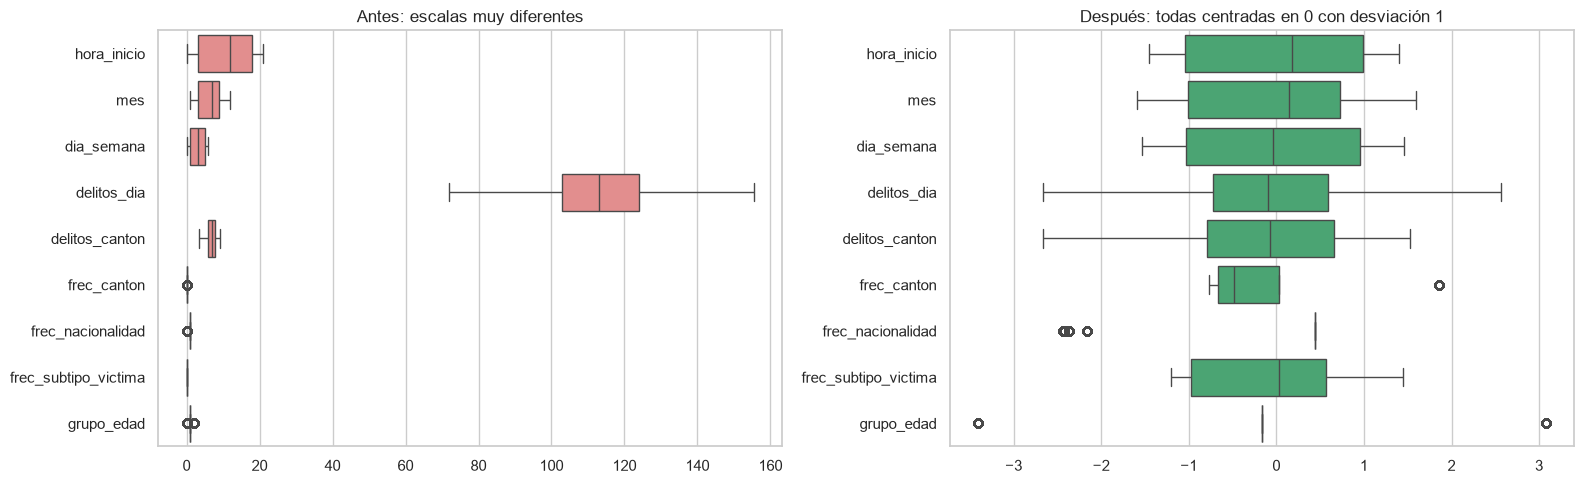

In [31]:
# Evidencia gráfica: escalas antes y después de estandarizar
fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=antes, orient="h", ax=ejes[0], color="lightcoral")
ejes[0].set_title("Antes: escalas muy diferentes")
sns.boxplot(data=datos_num[A_ESTANDARIZAR], orient="h", ax=ejes[1], color="mediumseagreen")
ejes[1].set_title("Después: todas centradas en 0 con desviación 1")
plt.tight_layout()
plt.show()

## 12. Correlación entre variables
Se usan dos medidas:
1. **Pearson** para las variables numéricas (relación lineal entre −1 y 1).
2. **V de Cramér** para medir la asociación entre cada variable **categórica original** y el delito
   (0 = sin relación, 1 = relación perfecta). Pearson no es adecuado para variables nominales como el delito.

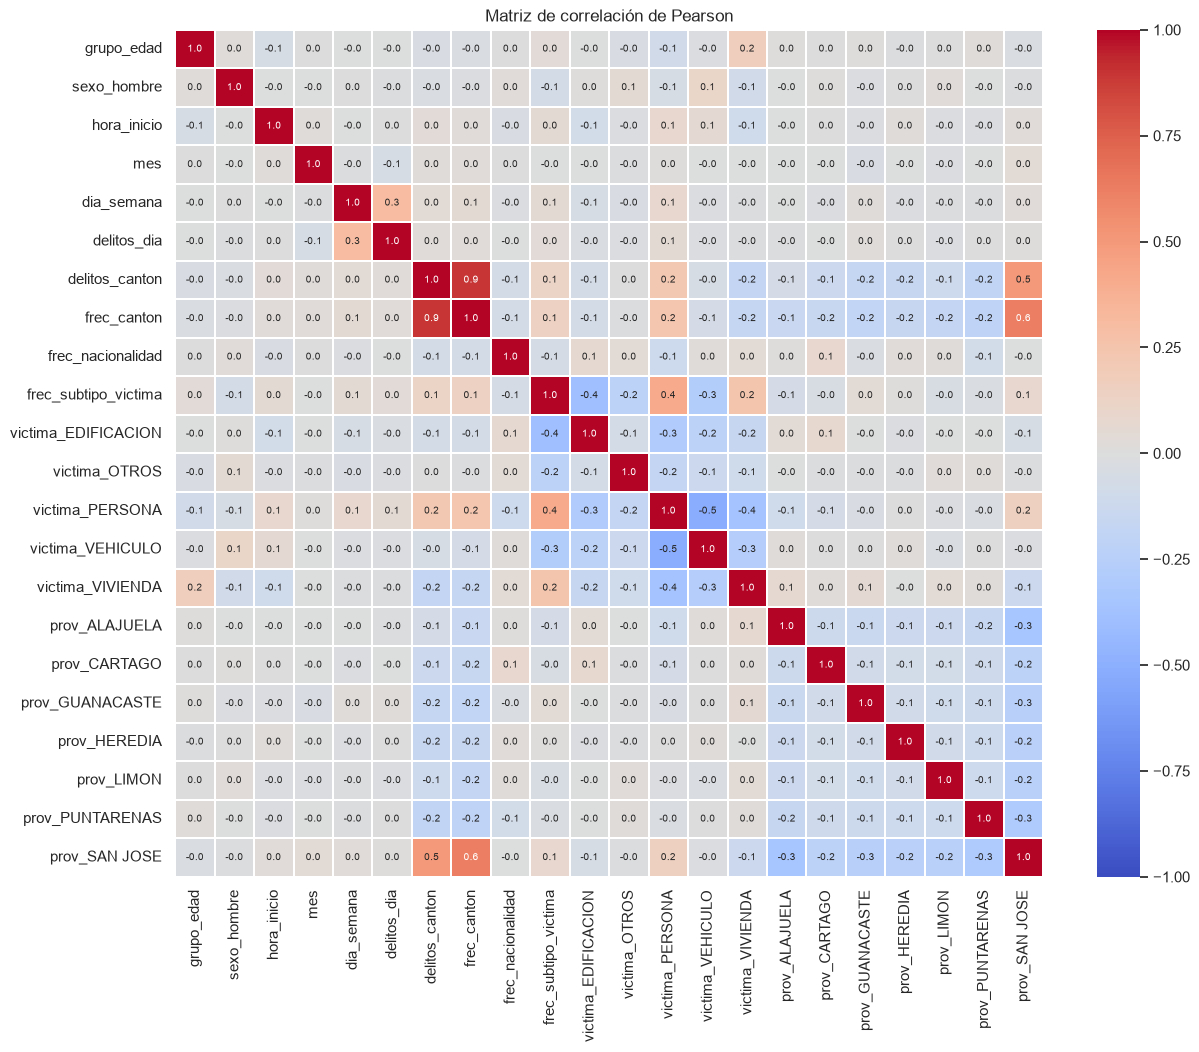

In [32]:
# 12.1 Matriz de correlación de Pearson (variables numéricas, sin la variable dependiente)
variables = datos_num.drop(columns="delito")
correlacion = variables.corr(method="pearson")

plt.figure(figsize=(14, 11))
sns.heatmap(correlacion, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, linewidths=0.3)
plt.title("Matriz de correlación de Pearson")
plt.show()

In [33]:
# Pares de variables con correlación fuerte (|r| >= 0.5)
pares = (correlacion.where(np.triu(np.ones(correlacion.shape, dtype=bool), k=1))
         .stack().rename("r").reset_index())
pares = pares[pares["r"].abs() >= 0.5].sort_values("r", key=abs, ascending=False)
pares

,level_0,level_1,r
139,delitos_canton,frec_canton,0.891555
175,frec_canton,prov_SAN JOSE,0.622940
277,victima_PERSONA,victima_VEHICULO,-0.509100


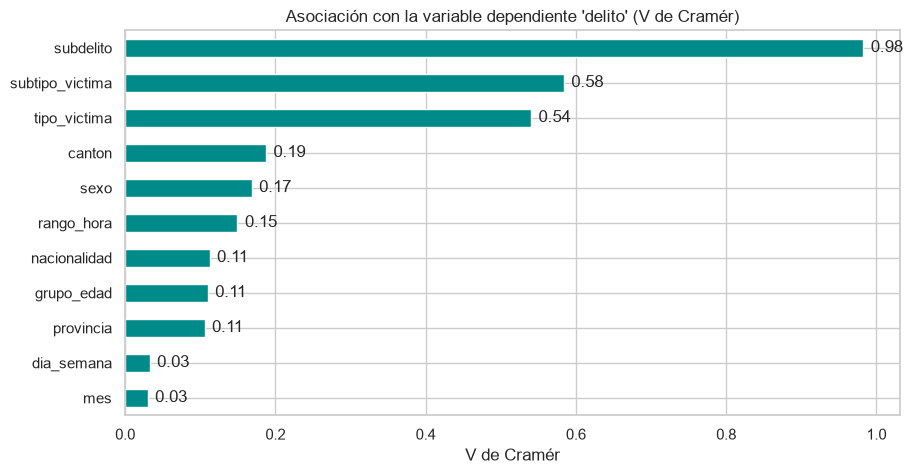

In [34]:
# 12.2 Asociación de cada variable categórica con el delito (V de Cramér)
from scipy.stats import chi2_contingency

def v_cramer(x, y):
    """Mide la asociación entre dos variables categóricas (0 a 1)."""
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

candidatas = ["subdelito", "tipo_victima", "subtipo_victima", "rango_hora", "grupo_edad",
              "sexo", "nacionalidad", "provincia", "canton", "mes", "dia_semana"]
asociacion = pd.Series({c: v_cramer(df[c], df["delito"]) for c in candidatas}).sort_values()

ax = asociacion.plot(kind="barh", color="darkcyan", figsize=(10, 5))
ax.set_title("Asociación con la variable dependiente 'delito' (V de Cramér)")
ax.set_xlabel("V de Cramér")
for i, v in enumerate(asociacion):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
plt.show()

**Hallazgos de correlación**
- **Entre variables numéricas (Pearson)** casi todas las correlaciones son débiles. Las fuertes son:
  - `delitos_canton` y `frec_canton` (**r = 0,89**): miden lo mismo (cuántos delitos tiene el cantón), una en
    logaritmo y otra en proporción. Son redundantes; para un modelo lineal convendría usar solo una.
  - `frec_canton` y `prov_SAN JOSE` (**r = 0,62**): los cantones con más delitos están en San José.
  - `victima_PERSONA` y `victima_VEHICULO` (**r = −0,51**): son categorías excluyentes del mismo one-hot.
- **Con la variable dependiente (V de Cramér):**
  - `subdelito` (**0,98**) está casi perfectamente asociado, porque es una subdivisión del mismo delito.
    Esto confirma que debía excluirse: usarlo sería hacer trampa (fuga de información).
  - `subtipo_victima` (**0,58**) y `tipo_victima` (**0,54**) son los mejores predictores legítimos:
    por ejemplo, si la víctima es un vehículo, el delito es casi siempre robo de vehículo o tacha.
  - `canton`, `sexo`, `rango_hora`, `nacionalidad`, `grupo_edad` y `provincia` tienen asociación **débil**
    (0,10–0,19); `mes` y `dia_semana` prácticamente **no se relacionan** con el tipo de delito (≈ 0,03).

## 13. Variable dependiente y modelo candidato
**Variable dependiente: `delito`** (tipo de delito: hurto, asalto, robo, robo de vehículo, tacha de vehículo u homicidio).

Es la variable que tiene sentido **predecir** a partir de las demás: *dado el lugar, la hora, el día y el perfil de la
víctima, ¿qué tipo de delito es más probable?* Esto ayudaría al OIJ a planificar patrullajes y prevención.

**Tipo de problema:** como la variable es **categórica con 6 clases**, es un problema de **clasificación multiclase**
(no de regresión).

**Modelo candidato: Bosque Aleatorio (*Random Forest*)**
- Funciona bien con muchas variables codificadas (one-hot y frecuencias) y con relaciones **no lineales**
  (por ejemplo, la hora influye distinto según la provincia).
- Las clases están **desbalanceadas** (homicidio ≈ 2 %); Random Forest permite compensarlo con `class_weight="balanced"`.
- Entrega la **importancia de cada variable**, útil para explicar los resultados.

**Alternativas estudiadas:** Árbol de decisión (más fácil de interpretar), KNN (aprovecha la estandarización)
y Regresión logística multinomial (modelo base lineal).

A continuación, una verificación rápida (no solicitada por el enunciado) para respaldar la elección:

Exactitud de la línea base (predecir siempre la clase más común): 0.330
Exactitud Random Forest:  0.697
F1 macro Random Forest:   0.663


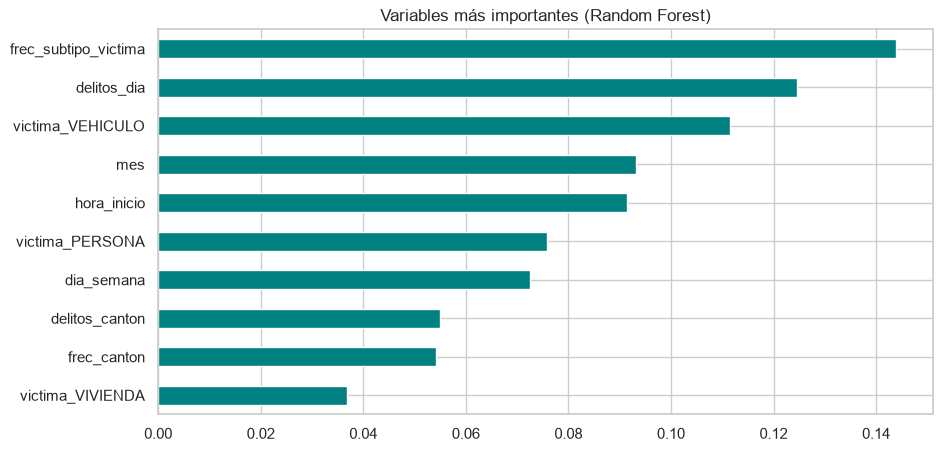

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

X = datos_num.drop(columns="delito")
y = datos_num["delito"]
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

modelo = RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                random_state=42, n_jobs=-1)
modelo.fit(X_ent, y_ent)
pred = modelo.predict(X_pru)

linea_base = y_pru.value_counts(normalize=True).max()
print(f"Exactitud de la línea base (predecir siempre la clase más común): {linea_base:.3f}")
print(f"Exactitud Random Forest:  {accuracy_score(y_pru, pred):.3f}")
print(f"F1 macro Random Forest:   {f1_score(y_pru, pred, average='macro'):.3f}")

importancia = pd.Series(modelo.feature_importances_, index=X.columns).sort_values().tail(10)
importancia.plot(kind="barh", color="teal", title="Variables más importantes (Random Forest)")
plt.show()

**Resultado de la verificación**
- Predecir siempre la clase más común (hurto) acierta un **33 %**; Random Forest acierta un **≈ 70 %**
  (F1 macro ≈ 0,66). El modelo sí aprende patrones reales del conjunto de datos.
- La clase más difícil es **homicidio** (F1 ≈ 0,43) porque solo representa el 2 % de los casos;
  ahí ayudaría ajustar hiperparámetros o aplicar técnicas de balanceo (sobremuestreo).
- Las variables más importantes son el **subtipo de víctima**, la cantidad de delitos del día, si la víctima es un
  vehículo, el mes y la hora. El tipo y subtipo de víctima coinciden con el análisis de correlación. `mes` y
  `delitos_dia` aparecen más arriba de lo esperado porque Random Forest tiende a favorecer las variables con
  muchos valores distintos.

## 14. Guardar el conjunto de datos resultante
Se guarda el dataset final, con **todas las actividades del EDA aplicadas** (nulos imputados, atípicos tratados,
tipos convertidos, categóricas codificadas y variables estandarizadas), en el archivo **`data_process.csv`**.

In [36]:
datos_num.to_csv("data_process.csv", index=False, encoding="utf-8")

# Verificación: se vuelve a leer el archivo guardado
verificacion = pd.read_csv("data_process.csv")
print("Archivo guardado: data_process.csv")
print("Dimensiones:", verificacion.shape, "| Nulos:", verificacion.isna().sum().sum())
verificacion.head()

Archivo guardado: data_process.csv
Dimensiones: (40947, 23) | Nulos: 0


,grupo_edad,sexo_hombre,hora_inicio,mes,dia_semana,delitos_dia,delitos_canton,frec_canton,frec_nacionalidad,frec_subtipo_victima,victima_EDIFICACION,victima_OTROS,victima_PERSONA,victima_VEHICULO,victima_VIVIENDA,prov_ALAJUELA,prov_CARTAGO,prov_GUANACASTE,prov_HEREDIA,prov_LIMON,prov_PUNTARENAS,prov_SAN JOSE,delito
0,-0.165137,0,-1.455886,-1.592767,-1.534431,-1.223036,1.525856,1.852731,-2.161822,1.440573,0,0,1,0,0,0,0,0,0,0,0,1,0
1,-0.165137,1,0.993156,-1.592767,-0.040060,-1.536320,-0.023161,-0.463408,0.436157,1.440573,0,0,1,0,0,0,0,0,0,0,0,1,0
2,-0.165137,0,-0.639539,-1.592767,0.956188,1.220584,-1.434164,-0.734035,0.436157,1.440573,0,0,1,0,0,0,0,0,0,0,0,1,0
3,-0.165137,1,-1.047712,-1.592767,-0.538183,-0.283182,1.525856,1.852731,-2.161822,1.440573,0,0,1,0,0,0,0,0,0,0,0,1,0
4,-0.165137,1,-1.047712,-1.592767,-0.538183,0.030103,0.244148,-0.323702,-2.161822,1.440573,0,0,1,0,0,0,0,0,1,0,0,0,0


## Conclusiones
1. El archivo del OIJ tenía un **encabezado desalineado** y filas mal delimitadas; fue necesario corregir la lectura
   antes de cualquier análisis. Revisar la estructura cruda es el primer paso de todo EDA.
2. No había nulos explícitos, pero sí **nulos disfrazados** ("Desconocido") en un 6–7 % de los datos de la víctima.
   No son aleatorios: dependen del tipo de víctima, por eso se imputaron con la moda por grupo.
3. Al ser un dataset categórico, los atípicos se estudiaron en **variables derivadas**. Se recortaron los días
   extremos y se aplicó logaritmo a la concentración de delitos por cantón.
4. Las variables se convirtieron a tipos adecuados, se codificaron según su naturaleza (ordinal, binaria, one-hot,
   frecuencia) y se estandarizaron, dejando un dataset 100 % numérico y sin nulos: **`data_process.csv`**
   (40 947 filas × 23 columnas).
5. La variable dependiente es **`delito`**; es un problema de **clasificación multiclase** y **Random Forest**
   es un buen candidato (≈ 70 % de exactitud frente al 33 % de la línea base).